# Braki danych

**Plan notatnika:**
1. Braki danych – skąd się biorą i co z nimi zrobić
2. Dane
3. Wykrywanie braków
4. Usuwanie braków – `dropna()`
5. Uzupełnianie w pandas – `fillna()`
6. Uzupełnianie w scikit-learn – `SimpleImputer`
7. Wskaźnik braków i `KNNImputer`
8. Braki w szeregach czasowych
9. Podsumowanie

Dokumentacja: [scikit-learn.org/stable/modules/impute.html](https://scikit-learn.org/stable/modules/impute.html)

## 1. Braki danych – skąd się biorą i co z nimi zrobić

Braki (`NaN`) powstają, gdy ktoś nie wypełnił pola, czujnik zawiódł albo dane nie zostały połączone. Większość modeli scikit-learn **nie przyjmuje** `NaN` (zgłasza błąd). Wyjątkiem są m.in. `HistGradientBoosting*` oraz drzewa i lasy w nowszych wersjach biblioteki.

**Co można zrobić:**

| Strategia | Kiedy |
|---|---|
| Usunąć wiersze | braków jest bardzo mało, a danych dużo |
| Usunąć kolumnę | większość wartości kolumny jest pusta |
| Wstawić stałą wartość | brak ma konkretne znaczenie (np. `'brak'`, `0`) |
| Wstawić statystykę (średnia, mediana, najczęstsza) | najprostsza i najczęstsza metoda |
| Wstawić wartość przewidzianą z innych kolumn | braki są liczne i istotne (`KNNImputer`) |

Warto też zapytać, **dlaczego** wartości brakują. Czasem sam brak jest informacją (np. klient nie podał telefonu), wtedy dodajemy kolumnę-wskaźnik.

## 2. Dane

In [1]:
import numpy as np
import pandas as pd
import sklearn

sklearn.__version__

'1.9.0'

In [2]:
data = {
    'size': ['XL', 'L', 'M', np.nan, 'M', 'M'],
    'color': ['red', 'green', 'blue', 'green', 'red', 'green'],
    'gender': ['female', 'male', np.nan, 'female', 'female', 'male'],
    'price': [199.0, 89.0, np.nan, 129.0, 79.0, 89.0],
    'weight': [500, 450, 300, np.nan, 410, np.nan],
    'bought': ['yes', 'no', 'yes', 'no', 'yes', 'no']
}

df_raw = pd.DataFrame(data)
df = df_raw.copy()
df

,size,color,gender,price,weight,bought
0,XL,red,female,199.0,500.0,yes
1,L,green,male,89.0,450.0,no
2,M,blue,NaN,NaN,300.0,yes
3,NaN,green,female,129.0,NaN,no
4,M,red,female,79.0,410.0,yes
5,M,green,male,89.0,NaN,no


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   size    5 non-null      str    
 1   color   6 non-null      str    
 2   gender  5 non-null      str    
 3   price   5 non-null      float64
 4   weight  4 non-null      float64
 5   bought  6 non-null      str    
dtypes: float64(2), str(4)
memory usage: 494.0 bytes


## 3. Wykrywanie braków

`isna()` zwraca tablicę `True/False` (`isnull()` to jego alias).

In [4]:
df.isna()

,size,color,gender,price,weight,bought
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,False,True,True,False,False
3,True,False,False,False,True,False
4,False,False,False,False,False,False
5,False,False,False,False,True,False


In [5]:
# liczba braków w kolumnach
df.isna().sum()

size      1
color     0
gender    1
price     1
weight    2
bought    0
dtype: int64

In [6]:
# łączna liczba braków
df.isna().sum().sum()

np.int64(5)

In [7]:
# odsetek braków w kolumnach
df.isna().mean().round(2)

size      0.17
color     0.00
gender    0.17
price     0.17
weight    0.33
bought    0.00
dtype: float64

In [10]:
# wiersze z brakiem w kolumnie 'weight'
df[df['weight'].isna()]

,size,color,gender,price,weight,bought
3,NaN,green,female,129.0,NaN,no
5,M,green,male,89.0,NaN,no


In [11]:
# wiersze z jakimkolwiek brakiem
df[df.isna().any(axis=1)]

,size,color,gender,price,weight,bought
2,M,blue,NaN,NaN,300.0,yes
3,NaN,green,female,129.0,NaN,no
5,M,green,male,89.0,NaN,no


## 4. Usuwanie braków – `dropna()`

Domyślnie usuwa **wiersze** zawierające choć jeden brak. Metoda zwraca nową ramkę, oryginał zostaje bez zmian.

In [12]:
df.dropna()

,size,color,gender,price,weight,bought
0,XL,red,female,199.0,500.0,yes
1,L,green,male,89.0,450.0,no
4,M,red,female,79.0,410.0,yes


Z 6 wierszy zostało 3: straciliśmy połowę danych. Można ograniczyć usuwanie do wybranych kolumn albo usunąć kolumny:

In [13]:
# tylko wiersze, w których brakuje 'weight'
df.dropna(subset=['weight'])

,size,color,gender,price,weight,bought
0,XL,red,female,199.0,500.0,yes
1,L,green,male,89.0,450.0,no
2,M,blue,NaN,NaN,300.0,yes
4,M,red,female,79.0,410.0,yes


In [14]:
# kolumny zawierające braki
df.dropna(axis=1)

,color,bought
0,red,yes
1,green,no
2,blue,yes
3,green,no
4,red,yes
5,green,no


## 5. Uzupełnianie w pandas – `fillna()`

`fillna()` przyjmuje jedną wartość dla całej ramki albo **słownik** z wartością dla każdej kolumny. Wynik przypisujemy do zmiennej (metoda nie modyfikuje ramki w miejscu).

In [16]:
df

,size,color,gender,price,weight,bought
0,XL,red,female,199.0,500.0,yes
1,L,green,male,89.0,450.0,no
2,M,blue,NaN,NaN,300.0,yes
3,NaN,green,female,129.0,NaN,no
4,M,red,female,79.0,410.0,yes
5,M,green,male,89.0,NaN,no


In [15]:
df_filled = df.fillna({
    'size': 'L',                      # stała wartość
    'gender': 'brak',                 # etykieta "brak"
    'price': df['price'].median(),    # mediana
    'weight': df['weight'].mean(),    # średnia
})
df_filled

,size,color,gender,price,weight,bought
0,XL,red,female,199.0,500.0,yes
1,L,green,male,89.0,450.0,no
2,M,blue,brak,89.0,300.0,yes
3,L,green,female,129.0,415.0,no
4,M,red,female,79.0,410.0,yes
5,M,green,male,89.0,415.0,no


In [18]:
df_filled.isna().sum()

size      0
color     0
gender    0
price     0
weight    0
bought    0
dtype: int64

## 6. Uzupełnianie w scikit-learn – `SimpleImputer`

`SimpleImputer` działa zgodnie ze schematem `fit` / `transform`. Zapamiętuje wartość wstawianą w braki (np. średnią), dzięki czemu **tę samą wartość** można użyć na zbiorze testowym i na nowych danych.

Parametr `strategy`:
- `'mean'` – średnia (tylko liczby),
- `'median'` – mediana (tylko liczby, odporna na wartości odstające),
- `'most_frequent'` – najczęstsza wartość (liczby i tekst),
- `'constant'` – stała podana w `fill_value`.

In [21]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='mean')
imputer.fit(df[['weight']])

# wartość, którą imputer wstawi w braki
imputer.statistics_

array([415.])

In [22]:
imputer.transform(df[['weight']])

array([[500.],
       [450.],
       [300.],
       [415.],
       [410.],
       [415.]])

In [23]:
# stała wartość liczbowa
SimpleImputer(strategy='constant', fill_value=99.0).fit_transform(df[['price']])

array([[199.],
       [ 89.],
       [ 99.],
       [129.],
       [ 79.],
       [ 89.]])

In [24]:
# najczęstsza wartość dla kategorii
SimpleImputer(strategy='most_frequent').fit_transform(df[['size']])

array([['XL'],
       ['L'],
       ['M'],
       ['M'],
       ['M'],
       ['M']], dtype=object)

**Wiele kolumn naraz.** Liczby uzupełniamy medianą, kategorie najczęstszą wartością. Łączymy to w `ColumnTransformer` (patrz notatnik 01):

In [25]:
from sklearn.compose import ColumnTransformer

imputer_all = ColumnTransformer(
    transformers=[
        ('liczby', SimpleImputer(strategy='median'), ['price', 'weight']),
        ('kategorie', SimpleImputer(strategy='most_frequent'), ['size', 'gender']),
    ],
    remainder='passthrough',            # pozostałe kolumny bez zmian
    verbose_feature_names_out=False,
)
imputer_all.set_output(transform='pandas')

df_imputed = imputer_all.fit_transform(df)
df_imputed

,price,weight,size,gender,color,bought
0,199.0,500.0,XL,female,red,yes
1,89.0,450.0,L,male,green,no
2,89.0,300.0,M,female,blue,yes
3,129.0,430.0,M,female,green,no
4,79.0,410.0,M,female,red,yes
5,89.0,430.0,M,male,green,no


In [26]:
df_imputed.isna().sum().sum()

np.int64(0)

**Pamiętaj:** w prawdziwym projekcie `fit` wykonujemy **tylko na zbiorze treningowym**. Medianę czy średnią liczymy z danych treningowych, a na testowych stosujemy samo `transform` (zasada ta sama co przy skalowaniu w notatniku 01).

## 7. Wskaźnik braków i `KNNImputer`

### Wskaźnik braków

Parametr `add_indicator=True` dodaje kolumny `missingindicator_*` z informacją, **które wartości były uzupełnione**. Model może wykorzystać fakt, że czegoś brakowało.

In [27]:
imp_ind = SimpleImputer(strategy='median', add_indicator=True)
imp_ind.set_output(transform='pandas')
imp_ind.fit_transform(df[['price', 'weight']])

,price,weight,missingindicator_price,missingindicator_weight
0,199.0,500.0,0.0,0.0
1,89.0,450.0,0.0,0.0
2,89.0,300.0,1.0,0.0
3,129.0,430.0,0.0,1.0
4,79.0,410.0,0.0,0.0
5,89.0,430.0,0.0,1.0


### KNNImputer

Uzupełnia brak średnią wartości z $k$ najbardziej **podobnych wierszy** (na podstawie pozostałych kolumn). Działa tylko na liczbach. Ponieważ używa odległości, kolumny warto wcześniej przeskalować.

In [28]:
df

,size,color,gender,price,weight,bought
0,XL,red,female,199.0,500.0,yes
1,L,green,male,89.0,450.0,no
2,M,blue,NaN,NaN,300.0,yes
3,NaN,green,female,129.0,NaN,no
4,M,red,female,79.0,410.0,yes
5,M,green,male,89.0,NaN,no


In [22]:
from sklearn.impute import KNNImputer

knn = KNNImputer(n_neighbors=2)
knn.set_output(transform='pandas')
knn.fit_transform(df[['price', 'weight']])

,price,weight
0,199.0,500.0
1,89.0,450.0
2,84.0,300.0
3,129.0,430.0
4,79.0,410.0
5,89.0,430.0


## 8. Braki w szeregach czasowych

W szeregach czasowych kolejność obserwacji ma znaczenie, więc sensowne są inne metody niż średnia:
- `interpolate()` – łączy sąsiednie punkty linią prostą,
- `ffill()` – powtarza ostatnią znaną wartość (*forward fill*),
- `bfill()` – bierze następną znaną wartość (*backward fill*).

In [29]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

price = pd.Series(
    [108, 109, 110, 110, 109, np.nan, np.nan, 112, 111, 111],
    index=pd.date_range('2020-01-01 09:00', periods=10, freq='h'),
    name='price',
)
price

Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 3 ("axes.prop_cycle: cycler('color', ['#123D98', '#C21E3C', '#E2A713', '#00AEEF', '#7F3F98'])"): Key axes.prop_cycle: "cycler('color', ['" is not a valid cycler construction: Could not parse "cycler('color', ['": unterminated string literal (detected at line 1) (<unknown>, line 1)
Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 6 ('grid.color: #e0e0e0'): Key grid.color: '' does not look like a color arg


2020-01-01 09:00:00    108.0
2020-01-01 10:00:00    109.0
2020-01-01 11:00:00    110.0
2020-01-01 12:00:00    110.0
2020-01-01 13:00:00    109.0
2020-01-01 14:00:00      NaN
2020-01-01 15:00:00      NaN
2020-01-01 16:00:00    112.0
2020-01-01 17:00:00    111.0
2020-01-01 18:00:00    111.0
Freq: h, Name: price, dtype: float64

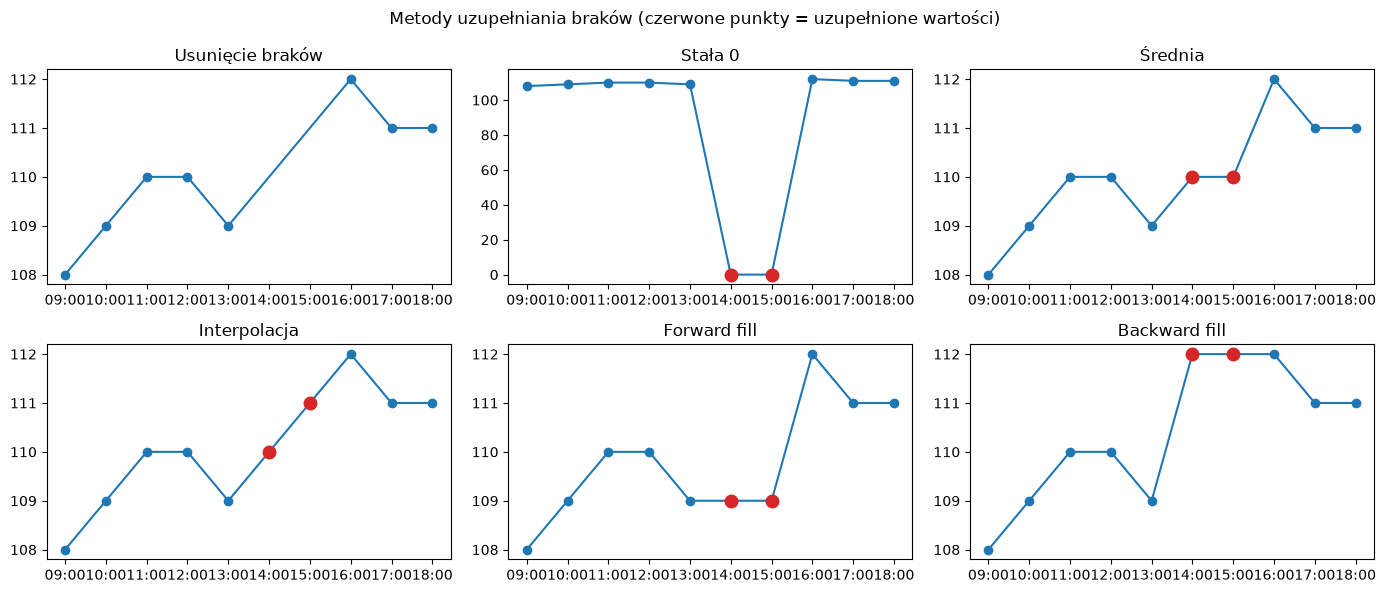

In [24]:
wersje = {
    'Usunięcie braków': price.dropna(),
    'Stała 0': price.fillna(0),
    'Średnia': price.fillna(price.mean()),
    'Interpolacja': price.interpolate(),
    'Forward fill': price.ffill(),
    'Backward fill': price.bfill(),
}

fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, (nazwa, seria) in zip(axes.ravel(), wersje.items()):
    uzupelnione = price.isna().reindex(seria.index, fill_value=False)
    ax.plot(seria.index, seria.values, 'o-', color='tab:blue')
    ax.plot(seria.index[uzupelnione], seria[uzupelnione], 'o', color='tab:red', markersize=9)
    ax.set_title(nazwa)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
fig.suptitle('Metody uzupełniania braków (czerwone punkty = uzupełnione wartości)')
plt.tight_layout()
plt.show()

**Jak czytać wykresy:**
- *Usunięcie braków* – linia po prostu łączy sąsiednie punkty, ale tracimy dwie godziny obserwacji.
- *Stała 0* – cena nagle spada do zera. Zwykle bezsensowne.
- *Średnia* – ignoruje trend (wartość z całego okresu w środku szeregu).
- *Interpolacja* – naturalne przejście między 109 a 112.
- *Forward fill* – cena „stoi” na ostatniej znanej wartości.
- *Backward fill* – używa przyszłej wartości.

**Uwaga na przecieki informacji.** Przy prognozowaniu model nie zna przyszłości. `bfill()`, `interpolate()` i średnia z całego szeregu używają danych z przyszłości, więc dla prognoz bezpieczny jest tylko `ffill()`.

## 9. Podsumowanie

| Zadanie | Narzędzie |
|---|---|
| Wykrycie braków | `df.isna().sum()` |
| Usunięcie wierszy / kolumn | `dropna()`, `dropna(subset=...)`, `dropna(axis=1)` |
| Szybkie uzupełnienie w pandas | `fillna({kolumna: wartość})` |
| Uzupełnienie w pipeline ML | `SimpleImputer` (`mean`, `median`, `most_frequent`, `constant`) |
| Informacja, że wartość brakowała | `add_indicator=True` |
| Uzupełnienie na podstawie podobnych wierszy | `KNNImputer` |
| Szeregi czasowe | `interpolate()`, `ffill()`, `bfill()` |

**Najważniejsze zasady:**
1. Najpierw sprawdź, ile i dlaczego brakuje danych.
2. Imputer uczymy (`fit`) tylko na zbiorze treningowym.
3. Wstawianie `0` jest zwykle złym pomysłem.
4. W szeregach czasowych uważaj na użycie przyszłych wartości.